# 01. 가설 기반 인과추론 (Causal Inference)

**제14회 2026 빅콘테스트 AI데이터 분석 분야 — 기후 위기에 따른 취약 상권 영향 분석**

| 항목 | 내용 |
|---|---|
| 목적 | EDA(`eda_analysis`)에서 세운 가설이 **상관이 아니라 인과**인지 확인한다 — 기상이 매출을 *바꾸는가*, 어떤 경로로, 누구에게 더 크게 |
| 입력 | `eda_analysis/data/processed/` 의 분석 테이블 (일·시간대·고객출신 × 지역 × 업종), `unit_profile` |
| 출력 | `data/processed/causal_unit_effects.parquet` (단위별 인과 효과 — 이후 단계 입력), `references/causal_hypotheses.csv` (가설 판정표) |
| 브랜치 | `ana-causal` |

**진행 순서**
1. 환경 설정·데이터 준비
2. 인과 질문 정의 — 가설, 인과 그래프(DAG), 식별 전략
3. CH1 호우는 매출을 줄이는가 — 고정효과 · 이벤트 스터디(위약 검정) · 무작위화 추론 · 지역 간 차분
4. CH2 폭염 효과는 인과인가, 교란인가 — 통제 수준별 비교 · 선행 위약 검정 · 소비 이동 검정
5. CH3 비는 '내리는 시간'에 매출을 줄이는가 — 같은 날 안의 시간대 비교
6. CH4 춘천 호우 피해는 외지 고객 이탈 때문인가 — 고객 출신 차분 · 삼중 차분 · 손실 분해
7. CH5 누가 더 타격을 받나 — 효과 이질성과 업체 규모
8. 문제 발굴로의 연결 — 단순 측정 vs 인과 추정, 지원 대상이 얼마나 달라지나
9. 가설 판정 종합·저장

> 금액은 모두 **신한카드 개인 결제 기준**(분석 포함 업종)이다. 대회 원본 행은 출력하지 않고 집계 결과만 보인다.

## 1. 환경 설정·데이터 준비

- 전처리·EDA 산출물은 `eda_analysis` 저장소에서 이미 만들었다. 이 저장소에서는 **필요한 가공 테이블만 `data/processed/`로 복사**해서 쓴다 (`data/`는 git 제외).
- 커널: `Python (bigcon)` (conda 가상환경 `bigcon`)

In [1]:
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
REF = ROOT / 'references'
EDA_PROC = ROOT.parent / 'eda_analysis' / 'data' / 'processed'   # 이전 저장소 산출물
PROC.mkdir(parents=True, exist_ok=True)
REF.mkdir(parents=True, exist_ok=True)

NEEDED = ['analysis_daily_group', 'analysis_slot_group', 'analysis_origin_group', 'unit_profile',
          'store_group_summary', 'weather_daily', 'weather_normal', 'weather_climate', 'flow_region_month',
          'model_daily_group']
for name in NEEDED:
    dst = PROC / f'{name}.parquet'
    if not dst.exists():
        shutil.copy2(EDA_PROC / f'{name}.parquet', dst)
print('data/processed:', ', '.join(sorted(p.stem for p in PROC.glob('*.parquet'))))
load = lambda name: pd.read_parquet(PROC / f'{name}.parquet')

# ---- 차트 스타일 (eda_analysis와 동일: 강남 = 파랑, 춘천 = 주황)
INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
REGION_COLOR = {'강남구': '#2a78d6', '춘천시': '#eb6834'}
MUTED = '#a3a29c'
plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
    'legend.frameon': False, 'legend.fontsize': 9,
})
REGIONS = ['강남구', '춘천시']
KEYS = ['region', 'industry_group']

data/processed: analysis_daily_group, analysis_origin_group, analysis_slot_group, causal_unit_effects, flow_region_month, model_daily_group, store_group_summary, unit_profile, weather_climate, weather_daily, weather_normal


In [2]:
WEATHER = {'rain_light': '비 약(0~5mm)', 'rain_mid': '비 보통(5~30mm)', 'rain_heavy': '비 강(30mm↑)',
           'heat_30_33': '폭염 30~33℃', 'heat_33': '폭염 33℃↑', 'snow': '눈', 'cold': '한파'}
CAL = 'C(dow) + is_holiday + is_payday_week'
CONTROLS = CAL + ' + C(week)'          # 기본 통제: 요일·공휴일·월급주간 + 주 고정효과

def prep(df):
    """log 매출 + 기상 처치 변수(0/1). 기준(0) = 체감 30℃ 미만·비 없음·눈·한파 아님."""
    df = df.copy()
    df['log_amt'] = np.log1p(df['amount'])
    df['week'] = df['date'].dt.isocalendar().week.astype(int)
    df['rain_light'] = ((df['rain_sum'] > 0) & (df['rain_sum'] < 5)).astype(int)
    df['rain_mid'] = ((df['rain_sum'] >= 5) & (df['rain_sum'] < 30)).astype(int)
    df['rain_heavy'] = (df['rain_sum'] >= 30).astype(int)
    df['heat_30_33'] = df['feels_like_max'].between(30, 33, inclusive='left').astype(int)
    df['heat_33'] = (df['feels_like_max'] >= 33).astype(int)
    df['snow'] = df['snow_day'].astype(int)
    df['cold'] = df['cold_day'].astype(int)
    df['log_rain'] = np.log1p(df['rain_sum'])
    for c in ['is_holiday', 'is_payday_week', 'is_offday']:
        df[c] = df[c].astype(int)
    return df

def region_total(df, keys=('date', 'region')):
    """업종 합계 (기상·달력은 날짜·지역 단위라 첫 값)."""
    keys = list(keys)
    other = [c for c in df.columns if c not in keys + ['amount', 'count', 'n_cells', 'industry_group', 'industry']]
    return df.groupby(keys, observed=True).agg({'amount': 'sum', **{c: 'first' for c in other}}).reset_index()

def fit_hac(formula, data, lags=7):
    """날짜순 정렬 후 OLS + Newey-West(HAC) 표준오차."""
    return smf.ols(formula, data=data.sort_values('date')).fit(cov_type='HAC', cov_kwds={'maxlags': lags})

def effects(res, terms, info=None):
    """계수 → 효과(%) = e^β − 1 과 95% 신뢰구간."""
    rows = []
    for t in terms:
        if t not in res.params:
            continue
        b, se = res.params[t], res.bse[t]
        rows.append({**(info or {}), 'term': WEATHER.get(t, t), 'coef': b, 'se': se,
                     'effect_pct': (np.exp(b) - 1) * 100, 'ci_low': (np.exp(b - 1.96 * se) - 1) * 100,
                     'ci_high': (np.exp(b + 1.96 * se) - 1) * 100, 'p_value': res.pvalues[t]})
    return rows

def active(data, terms):
    """그 지역·기간에 실제로 발생한 기상만 (예: 강남 한파 0일 → 제외)."""
    return [t for t in terms if data[t].nunique() > 1]

daily = prep(load('analysis_daily_group'))          # 날짜 × 지역 × 업종 (15)
tot = prep(region_total(load('analysis_daily_group')))  # 날짜 × 지역 (업종 합계)
unit = load('unit_profile')
print(f"일 × 지역 × 업종 {daily.shape} | 일 × 지역 {tot.shape} | 기간 {daily['date'].min():%Y-%m-%d} ~ {daily['date'].max():%Y-%m-%d}")
print('기상 처치 일수 (지역별):')
tot.groupby('region')[list(WEATHER)].sum().rename(columns=WEATHER)

일 × 지역 × 업종 (5520, 61) | 일 × 지역 (368, 58) | 기간 2025-07-01 ~ 2025-12-31
기상 처치 일수 (지역별):


,비 약(0~5mm),비 보통(5~30mm),비 강(30mm↑),폭염 30~33℃,폭염 33℃↑,눈,한파
region,,,,,,,
강남구,29,25,13,35,25,2,0
춘천시,25,19,17,34,19,3,3


## 2. 인과 질문 정의

### 2-1. EDA 가설 → 인과 가설
EDA 저장소(`eda_analysis`, 07단계)는 H1~H6을 **연관(association)** 수준에서 지지했다. 이 단계에서는 "기상이 매출을 **바꾼다**"고 말할 수 있는지, 그 **경로**와 **대상**이 무엇인지를 인과추론의 틀로 다시 묻는다.

| ID | 인과 가설 | 연결된 EDA 가설 | 처치(T) → 결과(Y) | 핵심 위협 | 식별 전략 |
|---|---|---|---|---|---|
| **CH1** | 강한 비(30mm↑)는 매출을 **줄인다** | H3·H4 | 강한 비 → log 매출 | 계절·성수기, 요일·연휴 | 주 고정효과, 이벤트 스터디(선행 위약), 무작위화 추론, 지역 간 차분 |
| **CH2** | 폭염의 '매출 증가'는 **교란(휴가철)**이고, 인과 효과는 업종 간 **소비 이동**이다 | H6 | 폭염 → log 매출 | 휴가철과 폭염의 동시 발생 | 통제 수준별 비교, 선행 위약 검정, 업종 가중합 = 0 검정 |
| **CH3** | 비는 **내리는 시간대**의 매출을 줄인다 | H5 | 시간대 강수 → 그 시간대 매출 | 그날의 모든 요인 | **같은 날·같은 업종 안**의 시간대 비교 (날짜×업종 고정효과) |
| **CH4** | 춘천 호우 피해는 **외지(방문) 고객 이탈**에서 나온다 | H4 | 강한 비 → 외지 − 현지 매출 차이 | 그날의 공통 충격 | 고객 출신 차분(날짜 고정효과), 지역 간 삼중 차분, 손실 분해 |
| **CH5** | 피해율은 **업체 규모로 설명되지 않는다** (규모 ≠ 타격) — 무엇이 피해율을 키우는가 | H1·H2 | 강한 비 × 업종 특성 → log 매출 | 업종 특성끼리의 상관 | 단위별 인과 효과의 정밀도 가중 메타 회귀 |

### 2-2. 왜 '날씨'는 인과추론에 유리한가
날씨는 상점·소비자가 고를 수 없는 **외생적 처치**다 (Dell, Jones & Olken, 2014). 단, 날씨에는 **계절성**이 있어 계절과 함께 움직이는 소비(휴가철·추석·연말)와 섞일 수 있다. 그래서 '같은 계절 안에서 날씨만 다른 날'을 비교해야 하며, 이것이 **주(week) 고정효과**의 역할이다.

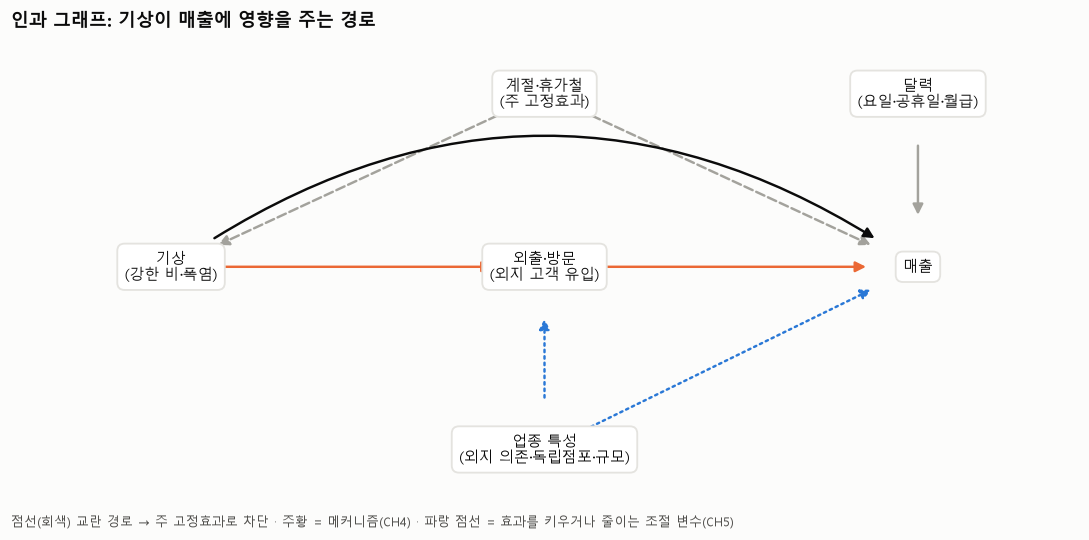

In [3]:
# 인과 그래프(DAG): 화살표 = 원인 → 결과. 회색 점선 = 통제해야 하는 뒷문 경로, 주황 = 메커니즘(매개)
nodes = {'계절·휴가철\n(주 고정효과)': (0.5, 0.88), '기상\n(강한 비·폭염)': (0.15, 0.52), '외출·방문\n(외지 고객 유입)': (0.5, 0.52),
         '매출': (0.85, 0.52), '달력\n(요일·공휴일·월급)': (0.85, 0.88), '업종 특성\n(외지 의존·독립점포·규모)': (0.5, 0.14)}
edges = [('계절·휴가철\n(주 고정효과)', '기상\n(강한 비·폭염)', 'conf'), ('계절·휴가철\n(주 고정효과)', '매출', 'conf'),
         ('기상\n(강한 비·폭염)', '외출·방문\n(외지 고객 유입)', 'mech'), ('외출·방문\n(외지 고객 유입)', '매출', 'mech'),
         ('기상\n(강한 비·폭염)', '매출', 'direct'), ('달력\n(요일·공휴일·월급)', '매출', 'prec'),
         ('업종 특성\n(외지 의존·독립점포·규모)', '외출·방문\n(외지 고객 유입)', 'mod'), ('업종 특성\n(외지 의존·독립점포·규모)', '매출', 'mod')]
style = {'conf': dict(color=MUTED, ls='--'), 'mech': dict(color='#eb6834', ls='-'), 'direct': dict(color=INK, ls='-'),
         'prec': dict(color=MUTED, ls='-'), 'mod': dict(color='#2a78d6', ls=':')}
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
for a, b, k in edges:
    ax.annotate('', xy=nodes[b], xytext=nodes[a],
                arrowprops=dict(arrowstyle='-|>', lw=1.6, shrinkA=34, shrinkB=34, mutation_scale=14,
                                connectionstyle='arc3,rad=-0.35' if k == 'direct' else 'arc3', **style[k]))
for name, (x, y) in nodes.items():
    ax.text(x, y, name, ha='center', va='center', fontsize=9.5, color=INK,
            bbox=dict(boxstyle='round,pad=0.5', fc='white', ec=GRID, lw=1.2))
ax.text(0.0, -0.02, '점선(회색) 교란 경로 → 주 고정효과로 차단 · 주황 = 메커니즘(CH4) · 파랑 점선 = 효과를 키우거나 줄이는 조절 변수(CH5)',
        fontsize=8.5, color=INK2, transform=ax.transAxes)
ax.set_title('인과 그래프: 기상이 매출에 영향을 주는 경로')
fig.tight_layout()

### 2-3. 식별 전략과 통제 원칙

| 원칙 | 적용 |
|---|---|
| **교란 차단** | 계절·휴가철은 기상과 매출 모두의 원인 → **주 고정효과**. 요일·공휴일·월급주간은 매출만의 원인이지만 오차를 줄이려고 통제 |
| **나쁜 통제 금지** | 유동인구·외지 고객 수는 기상의 **결과(매개 변수)**다. 통제하면 효과를 지워 버린다 → 통제하지 않고 CH4에서 **경로로** 분석 |
| **위약(placebo) 검정** | 미래의 비(내일·모레 비)는 오늘 매출의 원인일 수 없다 → 선행 계수가 0이어야 식별이 타당 |
| **추론 강건성** | 기상 일수가 적어(강한 비 13~17일) 점근 표준오차를 그대로 믿기 어렵다 → **무작위화 추론**(같은 주 안에서 날씨를 섞는 순열 검정) 병행 |
| **공통 충격 제거** | 같은 날 두 지역의 차이(지역 간 차분)·같은 날 고객 출신 간 차이(출신 차분)로 그날의 전국 공통 요인을 제거 |
| **다중 검정** | 업종 단위 검정은 Benjamini-Hochberg FDR(q<0.05) |

효과는 $\text{효과(\%)} = e^{\beta} - 1$로 해석하고, 표준오차는 Newey-West(7일) 또는 날짜 군집을 쓴다.

## 3. CH1 — 강한 비는 매출을 줄이는가

### 3-1. 기본 추정 (주 고정효과)
$$\log(\text{매출}_{t}+1) = \sum_k \beta_k\,\text{기상}_{k,t} + \text{요일} + \text{공휴일} + \text{월급주간} + \text{주}_{w(t)} + \varepsilon_t$$
지역 전체 매출(업종 합계)로 지역별로 추정한다.

In [4]:
ch1 = []
for r in REGIONS:
    d = tot[tot['region'] == r]
    use = active(d, WEATHER)
    res = fit_hac(f"log_amt ~ {' + '.join(use)} + {CONTROLS}", d)
    ch1 += effects(res, use, {'region': r, 'spec': '기본(이산)'})
    res_c = fit_hac(f"log_amt ~ log_rain + heat_33 + {' + '.join(t for t in use if t in ('snow', 'cold'))} + {CONTROLS}", d)
    ch1 += effects(res_c, ['log_rain'], {'region': r, 'spec': '연속(log 강수)'})
ch1 = pd.DataFrame(ch1)
ch1['days'] = [int(tot.loc[tot['region'] == r, k].sum()) if k in tot else np.nan
               for r, k in zip(ch1['region'], ch1['term'].map({v: k for k, v in WEATHER.items()}))]
ch1[['region', 'spec', 'term', 'days', 'effect_pct', 'ci_low', 'ci_high', 'p_value']].round(3)

,region,spec,term,days,effect_pct,ci_low,ci_high,p_value
0,강남구,기본(이산),비 약(0~5mm),29.000,2.075,-0.374,4.584,0.097
1,강남구,기본(이산),비 보통(5~30mm),25.000,-3.297,-7.233,0.806,0.114
2,강남구,기본(이산),비 강(30mm↑),13.000,-1.927,-5.254,1.517,0.269
3,강남구,기본(이산),폭염 30~33℃,35.000,-0.135,-4.086,3.979,0.948
4,강남구,기본(이산),폭염 33℃↑,25.000,1.982,-3.290,7.541,0.469
5,강남구,기본(이산),눈,2.000,-1.992,-11.115,8.067,0.686
6,강남구,연속(log 강수),log_rain,NaN,-1.067,-2.085,-0.038,0.042
7,춘천시,기본(이산),비 약(0~5mm),25.000,-0.635,-3.652,2.476,0.685
8,춘천시,기본(이산),비 보통(5~30mm),19.000,-5.616,-9.525,-1.539,0.007
9,춘천시,기본(이산),비 강(30mm↑),17.000,-7.238,-9.573,-4.842,0.000


- 강한 비 날 매출은 **춘천 −7.2%** [−9.6, −4.8], 보통 비 −5.6%다. 강남은 강한 비 −1.9%로 같은 방향이지만 신뢰구간이 0을 포함한다.
- 연속형(log 강수량)으로는 두 지역 모두 강수량이 늘수록 매출이 줄어든다 (춘천 −2.3%, 강남 −1.1% / log 1단위 ≈ 강수량 2.7배). 강남도 '비의 양'에 따른 작은 감소는 있지만, 강한 비 날을 따로 떼어 확정할 만큼 크지는 않다.
- 폭염은 두 지역 모두 효과가 0과 구분되지 않는다 (CH2에서 자세히).
- 아래 3-2~3-4는 이 결과가 **우연이나 교란이 아닌지** 세 가지 방법으로 점검한다.

### 3-2. 이벤트 스터디 — 미래의 비는 오늘 매출을 바꾸지 않아야 한다 (위약 검정)
강한 비 날을 기준(0일)으로 **3일 전 ~ 3일 후** 더미를 함께 넣는다.
- **선행(−3 ~ −1일)**: 비가 오기 전이므로 인과적으로 0이어야 한다. 0이 아니면 '비 오는 시기' 자체가 다른 날과 다르다는 뜻(교란).
- **시차(+1 ~ +3일)**: 비 온 뒤 미뤘던 소비가 돌아오는지(반등) — 순손실 계산은 3단계(피해 예측)에서 다룬다.

,region,선행 3개 결합 검정 χ²,p값,0일 효과(%),0일 p값
0,강남구,3.510,0.320,1.057,0.851
1,춘천시,4.910,0.179,-6.652,0.000


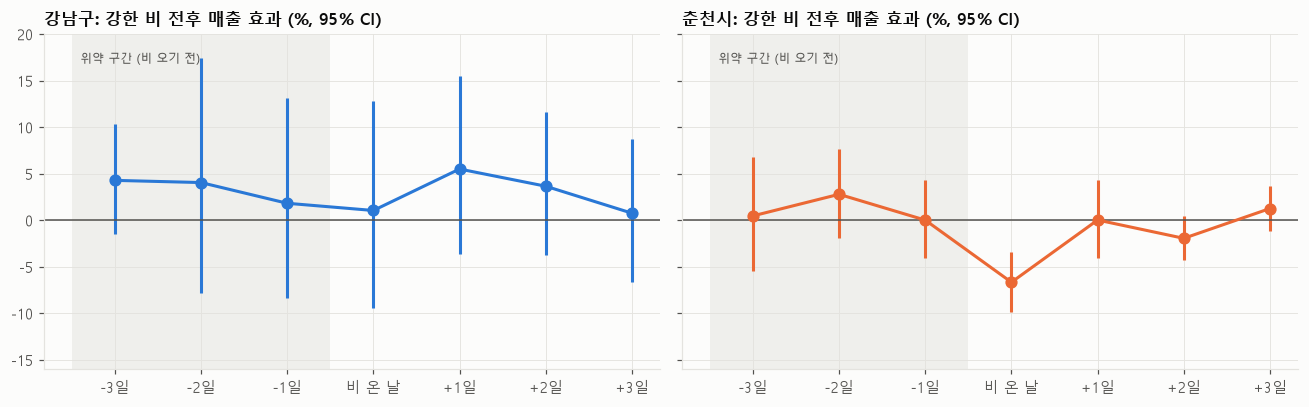

In [5]:
LEADS, LAGS = 3, 3
def lead_lag(d, col, prefix):
    d = d.sort_values('date').copy()
    names = []
    for h in range(-LEADS, LAGS + 1):
        n = f'{prefix}_m{-h}' if h < 0 else f'{prefix}_p{h}'
        d[n] = d[col].shift(h)
        names.append(n)
    return d.dropna(subset=names), names

es_rows, es_tests = [], []
for r in REGIONS:
    d = tot[tot['region'] == r]
    d, names = lead_lag(d, 'rain_heavy', 'H')
    other = [t for t in active(d, WEATHER) if t != 'rain_heavy']
    res = fit_hac(f"log_amt ~ {' + '.join(names + other)} + {CONTROLS}", d)
    for h, n in zip(range(-LEADS, LAGS + 1), names):
        b, se = res.params[n], res.bse[n]
        es_rows.append({'region': r, 'h': h, 'effect_pct': (np.exp(b) - 1) * 100,
                        'ci_low': (np.exp(b - 1.96 * se) - 1) * 100, 'ci_high': (np.exp(b + 1.96 * se) - 1) * 100})
    lead_names = [n for n in names if '_m' in n]
    wt = res.wald_test(', '.join(f'{n} = 0' for n in lead_names), scalar=True)
    es_tests.append({'region': r, '선행 3개 결합 검정 χ²': float(wt.statistic), 'p값': float(wt.pvalue),
                     '0일 효과(%)': (np.exp(res.params['H_p0']) - 1) * 100, '0일 p값': res.pvalues['H_p0']})
es = pd.DataFrame(es_rows)
display(pd.DataFrame(es_tests).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, r in zip(axes, REGIONS):
    e = es[es['region'] == r]
    ax.axvspan(-LEADS - 0.5, -0.5, color=GRID, alpha=0.5, lw=0)
    ax.text(-LEADS - 0.4, 18, '위약 구간 (비 오기 전)', fontsize=8, color=INK2, va='top')
    ax.errorbar(e['h'], e['effect_pct'], yerr=[e['effect_pct'] - e['ci_low'], e['ci_high'] - e['effect_pct']],
                fmt='o-', color=REGION_COLOR[r], capsize=0, ms=7)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(range(-LEADS, LAGS + 1), [f'{h:+d}일' if h else '비 온 날' for h in range(-LEADS, LAGS + 1)])
    ax.set_title(f'{r}: 강한 비 전후 매출 효과 (%, 95% CI)', fontsize=11)
ax.set_ylim(-16, 20)
fig.tight_layout()

- **선행 계수(비 오기 전 1~3일)는 두 지역 모두 0과 구분되지 않는다** (결합 검정 p값 참고). '비가 오는 시기'가 원래 매출이 낮은 시기라서 생긴 가짜 효과가 아니라는 근거다.
- 춘천은 **비 온 날(0일)에만 −6.7%로 뚜렷하게 감소**하고, 다음 날부터는 0 근처로 돌아온다 (+1일 0.0%, +2일 −1.9%, +3일 +1.3%, 모두 유의하지 않음). 비 온 날의 손실이 앞뒤 날의 매출 증가로 메워지는 뚜렷한 근거는 없다 — 정밀한 순손실 계산은 3단계(피해 예측)에서 한다.
- 강남은 0일 효과도 +1.1%로 0과 구분되지 않는다.

### 3-3. 무작위화 추론 — 날씨를 '같은 주 안에서' 섞으면 이런 효과가 우연히 나올 확률은?
강한 비 일수가 13~17일뿐이라 표준오차 근사가 불안정할 수 있다. 그래서 **Fisher의 무작위화 추론**을 쓴다.
- 귀무가설: 기상은 매출에 아무 영향이 없다 (sharp null).
- 같은 주 안의 날짜끼리 **그날의 기상 묶음 전체를 무작위로 재배치**한다 (주별 계절성은 유지, 요일·공휴일은 그대로).
- 재배치마다 같은 회귀를 다시 추정해 '우연히 나올 수 있는 계수의 분포'를 만들고, 실제 계수가 그 분포의 어디에 있는지 본다.

,region,term,effect_pct,RI p값 (양측),RI p값 (감소 단측)
0,강남구,비 강(30mm↑),-1.927,0.536,0.253
1,강남구,비 보통(5~30mm),-3.297,0.180,0.095
2,강남구,폭염 33℃↑,1.982,0.579,0.712
3,춘천시,비 강(30mm↑),-7.238,0.002,0.002
4,춘천시,비 보통(5~30mm),-5.616,0.009,0.004
5,춘천시,폭염 33℃↑,2.226,0.465,0.770


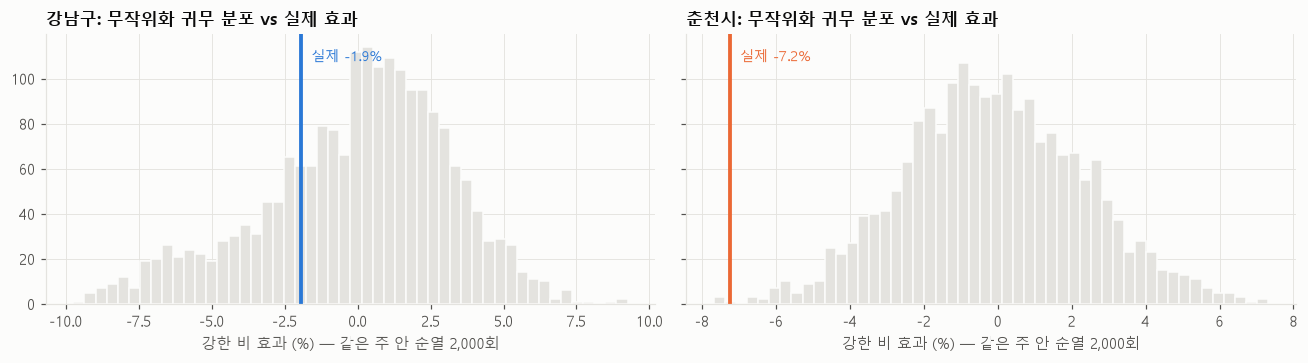

In [6]:
import patsy

def ri_test(d, target, n_perm=2000, seed=42):
    """주 안에서 기상 벡터를 순열 → target 계수의 귀무 분포. 반환: 실제 계수, 순열 계수 배열."""
    d = d.sort_values('date').reset_index(drop=True)
    use = active(d, WEATHER)
    y, X = patsy.dmatrices(f"log_amt ~ {' + '.join(use)} + {CONTROLS}", d, return_type='dataframe')
    j = list(X.columns).index(target)
    wcols = [list(X.columns).index(t) for t in use]
    beta = np.linalg.lstsq(X.values, y.values.ravel(), rcond=None)[0][j]
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(d['week'].values == w) for w in np.unique(d['week'])]
    W = X.values[:, wcols].copy()
    Xp = X.values.copy()
    null = np.empty(n_perm)
    for i in range(n_perm):
        perm = np.arange(len(d))
        for g in groups:
            perm[g] = rng.permutation(g)
        Xp[:, wcols] = W[perm]
        null[i] = np.linalg.lstsq(Xp, y.values.ravel(), rcond=None)[0][j]
    return beta, null

ri_rows, ri_null = [], {}
for r in REGIONS:
    d = tot[tot['region'] == r]
    for t in ['rain_heavy', 'rain_mid', 'heat_33']:
        b, null = ri_test(d, t)
        ri_null[(r, t)] = (b, null)
        ri_rows.append({'region': r, 'term': WEATHER[t], 'effect_pct': (np.exp(b) - 1) * 100,
                        'RI p값 (양측)': (np.abs(null) >= abs(b)).mean(), 'RI p값 (감소 단측)': (null <= b).mean()})
ri = pd.DataFrame(ri_rows)
display(ri.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, r in zip(axes, REGIONS):
    b, null = ri_null[(r, 'rain_heavy')]
    ax.hist((np.exp(null) - 1) * 100, bins=50, color=GRID, edgecolor=SURFACE)
    ax.axvline((np.exp(b) - 1) * 100, color=REGION_COLOR[r], lw=2.5)
    ax.text((np.exp(b) - 1) * 100, ax.get_ylim()[1] * 0.9, f'  실제 {(np.exp(b) - 1) * 100:+.1f}%', color=REGION_COLOR[r], fontsize=9)
    ax.set_xlabel('강한 비 효과 (%) — 같은 주 안 순열 2,000회')
    ax.set_title(f'{r}: 무작위화 귀무 분포 vs 실제 효과', fontsize=11)
fig.tight_layout()

- 춘천의 강한 비 효과(−7.2%)는 같은 주 안에서 날씨를 무작위로 섞은 2,000번 중 **0.2%에서만** 나오는 크기다 (RI p = 0.002). 보통 비도 p = 0.009. 점근 표준오차에 의존하지 않고도 춘천 호우 효과는 우연이 아니다.
- 강남의 강한 비 효과는 순열 분포 한가운데에 있어 **우연과 구분되지 않는다** (p = 0.54). 폭염은 두 지역 모두 우연과 구분되지 않는다 (p = 0.47~0.58).

### 3-4. 지역 간 차분 — 같은 날, 한 지역에만 비가 왔다면
같은 날의 **강남 − 춘천** 매출 차이를 쓰면, 그날 두 지역에 공통인 요인(전국 연휴·명절 분위기·경기·이벤트)이 모두 지워진다 (날짜 고정효과와 같다). 효과는 **두 지역의 날씨가 서로 달랐던 날**에서만 식별된다.

$$\log Y^{강남}_t - \log Y^{춘천}_t = \sum_k \big(\beta^{강남}_k W^{강남}_{k,t} - \beta^{춘천}_k W^{춘천}_{k,t}\big) + \text{요일} + \text{공휴일} + \text{주} + u_t$$

In [7]:
w = tot.pivot(index='date', columns='region')
dd = pd.DataFrame({'date': w.index, 'diff': (w[('log_amt', '강남구')] - w[('log_amt', '춘천시')]).values})
for k in ['rain_mid', 'rain_heavy', 'heat_33', 'snow']:
    dd[f'{k}_gn'] = w[(k, '강남구')].values
    dd[f'{k}_cc'] = w[(k, '춘천시')].values
cal = tot[tot['region'] == '강남구'][['date', 'dow', 'is_holiday', 'is_payday_week', 'week']]
dd = dd.merge(cal, on='date')
terms = [f'{k}_{s}' for k in ['rain_mid', 'rain_heavy', 'heat_33', 'snow'] for s in ['gn', 'cc']]
res_dd = fit_hac(f"diff ~ {' + '.join(terms)} + {CONTROLS}", dd)
rows = []
for k in ['rain_mid', 'rain_heavy', 'heat_33']:
    for s, r, sign in [('gn', '강남구', 1), ('cc', '춘천시', -1)]:
        b, se = sign * res_dd.params[f'{k}_{s}'], res_dd.bse[f'{k}_{s}']
        only = int(((dd[f'{k}_{s}'] == 1) & (dd[f"{k}_{'cc' if s == 'gn' else 'gn'}"] == 0)).sum())
        rows.append({'region': r, 'term': WEATHER[k], '그 지역에만 발생한 날': only, 'effect_pct': (np.exp(b) - 1) * 100,
                     'ci_low': (np.exp(b - 1.96 * se) - 1) * 100, 'ci_high': (np.exp(b + 1.96 * se) - 1) * 100,
                     'p_value': res_dd.pvalues[f'{k}_{s}']})
cross = pd.DataFrame(rows)
cross.round(3)

,region,term,그 지역에만 발생한 날,effect_pct,ci_low,ci_high,p_value
0,강남구,비 보통(5~30mm),13,-1.198,-4.643,2.371,0.506
1,춘천시,비 보통(5~30mm),7,-1.316,-6.468,4.120,0.628
2,강남구,비 강(30mm↑),2,-1.083,-7.322,5.575,0.743
3,춘천시,비 강(30mm↑),6,-8.067,-12.953,-2.907,0.003
4,강남구,폭염 33℃↑,8,-0.524,-4.412,3.523,0.796
5,춘천시,폭염 33℃↑,2,-0.581,-4.211,3.188,0.759


- 그날의 전국 공통 요인을 지운 뒤에도 **춘천의 강한 비 효과는 −8.1%** [−13.0, −2.9]로 남는다 (춘천에만 강한 비가 온 날 6일). 춘천 호우 효과는 '비 오는 날 전국적으로 무슨 일이 있었기 때문'이 아니다.
- 강남의 비 효과는 이 설계에서도 0과 구분되지 않는다 (강남에만 강한 비가 온 날은 2일뿐이라 검정력도 낮다).

**CH1 판정**: 춘천에서 강한 비는 매출을 **인과적으로 줄인다** (고정효과·위약 검정·무작위화 추론·지역 간 차분이 모두 같은 결론). 강남은 방향은 같지만 효과를 확정할 근거가 부족하다.

## 4. CH2 — 폭염 효과는 인과인가, 교란인가

### 4-1. 통제 수준을 높이면 폭염 효과는 어떻게 되나
교란(휴가철)이 있다면 통제를 강하게 할수록 효과가 0으로 줄어든다. 반대로 진짜 인과 효과라면 통제와 무관하게 남는다.

In [8]:
specs = {'① 통제 없음': '1', '② 월 + 요일': 'C(month) + C(dow)', '③ 주 + 요일·공휴일 (기본)': CONTROLS}
rows = []
for name, ctrl in specs.items():
    for r in REGIONS:
        d = tot[tot['region'] == r]
        use = active(d, WEATHER)
        res = fit_hac(f"log_amt ~ {' + '.join(use)} + {ctrl}", d)
        rows += effects(res, ['heat_30_33', 'heat_33', 'rain_heavy'], {'region': r, 'spec': name})
spec_cmp = pd.DataFrame(rows)
spec_cmp.pivot_table(index=['region', 'term'], columns='spec', values='effect_pct').round(2)

spec               ① 통제 없음  ② 월 + 요일  ③ 주 + 요일·공휴일 (기본)
region term                                            
강남구    비 강(30mm↑)   -5.130    -5.500             -1.930
       폭염 30~33℃    -5.370    -2.220             -0.130
       폭염 33℃↑       1.350     2.550              1.980
춘천시    비 강(30mm↑)   -7.320    -9.780             -7.240
       폭염 30~33℃    -2.140     0.440              2.370
       폭염 33℃↑       1.730     1.810              2.230

- 강남 '폭염 30~33℃'는 통제 없이 −5.4%였다가 주 고정효과에서 −0.1%로 사라진다. 강한 비도 강남은 −5.1% → −1.9%로 줄어든다. 즉 **통제가 약하면 계절 효과가 날씨 효과로 둔갑**한다.
- 춘천 강한 비는 통제 수준과 무관하게 −7%대로 유지된다 (교란에 흔들리지 않는 효과). 폭염 33℃↑는 어느 통제에서도 +2% 안팎이고 유의하지 않다.

### 4-2. 선행 위약 검정 — '내일의 폭염'이 오늘 매출과 관련 있다면 그것은 교란이다
폭염 더미의 **1~3일 전** 값을 함께 넣는다. 폭염이 오기 전 날들은 폭염의 영향을 받을 수 없으므로, 선행 계수가 0이 아니면 그 기간 자체가 원래 다른 시기(휴가철)라는 증거다. 통제 ②(월)와 ③(주)에서 비교한다.

In [9]:
rows = []
for name, ctrl in [('② 월 + 요일', 'C(month) + C(dow)'), ('③ 주 + 요일·공휴일 (기본)', CONTROLS)]:
    for r in REGIONS:
        d, names = lead_lag(tot[tot['region'] == r], 'heat_33', 'T')
        other = [t for t in active(d, WEATHER) if t not in ('heat_33', 'heat_30_33')]
        res = fit_hac(f"log_amt ~ {' + '.join(names + other)} + {ctrl}", d)
        lead_names = [n for n in names if '_m' in n]
        wt = res.wald_test(', '.join(f'{n} = 0' for n in lead_names), scalar=True)
        rows.append({'spec': name, 'region': r,
                     '선행 1~3일 평균 효과(%)': (np.exp(res.params[lead_names].mean()) - 1) * 100,
                     '선행 결합 검정 p값': float(wt.pvalue),
                     '폭염 당일 효과(%)': (np.exp(res.params['T_p0']) - 1) * 100, '당일 p값': res.pvalues['T_p0']})
pd.DataFrame(rows).round(3)

,spec,region,선행 1~3일 평균 효과(%),선행 결합 검정 p값,폭염 당일 효과(%),당일 p값
0,② 월 + 요일,강남구,-1.101,0.875,3.124,0.124
1,② 월 + 요일,춘천시,0.767,0.160,-1.501,0.260
2,③ 주 + 요일·공휴일 (기본),강남구,1.410,0.209,1.792,0.120
3,③ 주 + 요일·공휴일 (기본),춘천시,2.197,0.018,-0.218,0.868


### 4-3. 소비 이동 검정 — 업종마다 반대로 움직이고, 합치면 0인가
폭염의 인과 효과가 '전체 매출 감소'가 아니라 '업종 간 소비 이동'이라면 두 가지가 동시에 성립해야 한다.
1. **업종별 효과가 서로 다르다** (업종 × 폭염 상호작용 = 0 기각)
2. **매출 가중 평균 효과는 0이다** (늘어난 업종과 줄어든 업종이 상쇄)

지역별로 15개 업종을 한 회귀에 넣고(업종마다 자기 달력·주 효과), 날짜 군집 표준오차로 두 검정을 한다.

In [10]:
def pooled_industry(d):
    """업종별 달력·주 효과 + 업종별 기상 효과. 기준 업종 = 첫 업종(간편식)."""
    f = (f"log_amt ~ C(industry_group) * ({CONTROLS}) + C(industry_group) * ({' + '.join(active(d, WEATHER))})")
    return smf.ols(f, data=d).fit(cov_type='cluster', cov_kwds={'groups': d['date'].rank(method='dense').astype(int)})

def industry_effect_contrast(res, groups, term):
    """업종별 효과 = 기준 계수 + 상호작용 계수 → 각 업종의 선형결합 벡터."""
    names = list(res.params.index)
    vecs = {}
    for g in groups:
        v = np.zeros(len(names))
        v[names.index(term)] = 1
        inter = f'C(industry_group)[T.{g}]:{term}'
        if inter in names:
            v[names.index(inter)] = 1
        vecs[g] = v
    return vecs

reloc, pooled_res = [], {}
for r in REGIONS:
    d = daily[daily['region'] == r]
    res = pooled_industry(d)
    pooled_res[r] = res
    groups = sorted(d['industry_group'].unique())
    share = d.groupby('industry_group')['amount'].sum()
    share = share / share.sum()
    for term in ['heat_33', 'rain_heavy']:
        vecs = industry_effect_contrast(res, groups, term)
        inter = [n for n in res.params.index if n.endswith(f':{term}') and n.startswith('C(industry_group)')]
        het = res.wald_test(', '.join(f'{n} = 0' for n in inter), scalar=True)
        avg = sum(share[g] * vecs[g] for g in groups)
        tt = res.t_test(avg)
        ind_eff = {g: float(vecs[g] @ res.params.values) for g in groups}
        reloc.append({'region': r, 'term': WEATHER[term],
                      '① 업종 간 차이 검정 p값': float(het.pvalue),
                      '② 매출 가중 평균 효과(%)': (np.exp(float(tt.effect[0])) - 1) * 100,
                      '② 평균 효과 p값': float(tt.pvalue),
                      '증가 업종 수': sum(v > 0.01 for v in ind_eff.values()), '감소 업종 수': sum(v < -0.01 for v in ind_eff.values())})
reloc = pd.DataFrame(reloc)
reloc.round(4)

,region,term,① 업종 간 차이 검정 p값,② 매출 가중 평균 효과(%),② 평균 효과 p값,증가 업종 수,감소 업종 수
0,강남구,폭염 33℃↑,0.002,2.615,0.472,12,3
1,강남구,비 강(30mm↑),0.000,-0.428,0.879,4,10
2,춘천시,폭염 33℃↑,0.189,1.924,0.526,7,5
3,춘천시,비 강(30mm↑),0.000,-8.038,0.000,1,14


**CH2 판정 — 부분 지지**
- **폭염이 매출을 줄인다는 근거는 어느 설계에서도 나오지 않는다.** 폭염 당일 효과는 통제 수준과 무관하게 0과 구분되지 않는다 (4-1, 4-2).
- 선행 위약 검정(4-2)에서 춘천은 주 고정효과 아래에서도 '폭염 1~3일 전'에 +2.2%(p = 0.018)가 잡힌다. 폭염은 며칠씩 이어지는 **폭염 기간(휴가철 한가운데)**에 몰려 있어, 6개월 자료로는 폭염 자체의 효과를 그 시기의 소비와 깔끔하게 분리하기 어렵다는 뜻이다 → 폭염 효과 추정치는 **인과로 해석하지 않는다.**
- 소비 이동(4-3): **강남**은 업종별 폭염 효과가 서로 다르고(p = 0.002, 증가 12개·감소 3개) 매출 가중 평균은 0과 구분되지 않는다(+2.6%, p = 0.47) → 업종 간 소비 이동과 맞는다. **춘천**은 업종 간 차이도 유의하지 않아(p = 0.19) 폭염의 영향 자체가 확인되지 않는다.
- 대조: 강한 비는 춘천에서 15개 업종 중 14개가 감소하고 가중 평균이 −8.0%(p < 0.001)다 — **지역 전체의 진짜 손실**이다.
- → 이후 피해 예측·지원의 **중심 기상은 호우**로 둔다. 폭염은 '전체 피해'가 아니라 업종 간 재배분으로 보고, 다년 자료가 생기면 재검증할 대상으로 남긴다.

## 5. CH3 — 비는 '내리는 시간대'의 매출을 줄이는가

### 같은 날·같은 업종 안에서 시간대끼리 비교
카드 데이터1은 하루를 6시간 4구간으로 나눈다. 같은 날 같은 업종이라면 그날의 모든 요인(요일·명절·날씨 전반·경기)이 같으므로, **비가 내린 시간대와 안 내린 시간대의 매출 차이**는 그 시간대의 비 때문이라고 볼 수 있다.

$$\log Y_{u,t,s} = \beta\,\text{Rain}_{t,s} + \underbrace{\alpha_{u,t}}_{\text{날짜×업종}} + \underbrace{\gamma_{u,s}}_{\text{업종×시간대}} + \varepsilon_{u,t,s}$$

- $\alpha_{u,t}$: 그날 그 업종의 모든 것 (날짜 × 업종 고정효과 — 일 단위 교란을 전부 흡수)
- $\gamma_{u,s}$: 업종의 평소 시간대 패턴 (주점은 밤, 병원은 오전)
- $\text{Rain}_{t,s}$: 그 시간대 강수 1mm 이상. 표준오차는 날짜 군집
- 0 채움(소액 미집계)이 5%를 넘는 업종×시간대는 제외

두 고정효과는 교대 투영(alternating projections)으로 제거한 뒤 OLS로 추정한다 (Frisch–Waugh–Lovell).

In [11]:
slot = prep(load('analysis_slot_group'))
slot['slot_rain'] = (slot['slot_rain_sum'] >= 1).astype(float)
slot['slot_log_rain'] = np.log1p(slot['slot_rain_sum'])
zero = slot.groupby(['region', 'industry_group', 'time_slot'], observed=True)['n_cells'].apply(lambda s: (s == 0).mean())
keep = zero[zero <= 0.05].index
slot = slot.set_index(['region', 'industry_group', 'time_slot']).loc[lambda x: x.index.isin(keep)].reset_index()
slot['time_slot'] = slot['time_slot'].astype(str)
print(f"시간대 분석 표본: {len(slot):,}행 (업종×시간대 {len(keep)}개 / 120개 사용)")

def demean_2way(df, cols, g1, g2, tol=1e-10, max_iter=500):
    """두 고정효과(g1, g2)를 교대로 빼서 제거 (교대 투영)."""
    X = df[cols].astype(float).copy()
    for _ in range(max_iter):
        before = X.values.copy()
        X = X - X.groupby(df[g1]).transform('mean')
        X = X - X.groupby(df[g2]).transform('mean')
        if np.abs(X.values - before).max() < tol:
            break
    return X

def within_day(d, xcols):
    d = d.copy()
    d['g_day'] = d['region'] + '|' + d['industry_group'] + '|' + d['date'].dt.strftime('%m%d')
    d['g_slot'] = d['region'] + '|' + d['industry_group'] + '|' + d['time_slot']
    Z = demean_2way(d, ['log_amt'] + xcols, 'g_day', 'g_slot')
    res = sm.OLS(Z['log_amt'], Z[xcols]).fit(cov_type='cluster', cov_kwds={'groups': d['date'].rank(method='dense').astype(int)})
    return res

rows = []
for r in REGIONS:
    d = slot[slot['region'] == r]
    res = within_day(d, ['slot_rain'])
    rows += effects(res, ['slot_rain'], {'region': r, 'spec': '전체 시간대'})
    for s in ['00_05', '06_11', '12_17', '18_23']:
        d[f'rain_{s}'] = d['slot_rain'] * (d['time_slot'] == s)
    res_c = within_day(d, ['slot_log_rain'])
    rows += effects(res_c, ['slot_log_rain'], {'region': r, 'spec': '연속(log 강수)'})
    res_s = within_day(d, [f'rain_{s}' for s in ['00_05', '06_11', '12_17', '18_23']])
    rows += effects(res_s, [f'rain_{s}' for s in ['00_05', '06_11', '12_17', '18_23']], {'region': r, 'spec': '시간대별'})
ch3 = pd.DataFrame(rows)
ch3['term'] = ch3['term'].replace({'slot_rain': '그 시간대에 비(1mm↑)', 'slot_log_rain': 'log(1+시간대 강수) 1단위', 'rain_00_05': '00~05시 비', 'rain_06_11': '06~11시 비',
                                   'rain_12_17': '12~17시 비', 'rain_18_23': '18~23시 비'})
ch3[['region', 'spec', 'term', 'effect_pct', 'ci_low', 'ci_high', 'p_value']].round(4)

시간대 분석 표본: 20,976행 (업종×시간대 114개 / 120개 사용)


,region,spec,term,effect_pct,ci_low,ci_high,p_value
0,강남구,전체 시간대,그 시간대에 비(1mm↑),-1.308,-7.297,5.068,0.680
1,강남구,연속(log 강수),log(1+시간대 강수) 1단위,1.371,-1.010,3.809,0.262
2,강남구,시간대별,00~05시 비,-1.025,-13.008,12.609,0.876
3,강남구,시간대별,06~11시 비,-1.587,-8.160,5.456,0.650
4,강남구,시간대별,12~17시 비,-4.552,-10.262,1.521,0.139
5,강남구,시간대별,18~23시 비,2.257,-7.497,13.039,0.663
6,춘천시,전체 시간대,그 시간대에 비(1mm↑),-4.660,-10.323,1.361,0.127
7,춘천시,연속(log 강수),log(1+시간대 강수) 1단위,-1.544,-4.134,1.116,0.253
8,춘천시,시간대별,00~05시 비,-3.342,-15.421,10.463,0.618
9,춘천시,시간대별,06~11시 비,-3.242,-10.090,4.129,0.379


**CH3 판정 — 판단 보류**
- 춘천은 비가 내린 시간대의 매출이 같은 날 다른 시간대보다 **−4.7%** 낮고, 네 시간대 모두 같은 방향(−3 ~ −7%)이다. 하지만 같은 날 안의 비교로 좁히면 신뢰구간이 0을 포함한다 (p = 0.13). 강남은 −1.3%로 효과가 보이지 않는다.
- 즉 **'비가 온 날'의 효과(CH1)는 확실하지만, 그 안에서 '비가 온 시간'이 추가로 만드는 차이는 이 자료로 확정할 수 없다.** EDA에서 시간대별 효과가 크게 나온 것(춘천 −6 ~ −10%)은 상당 부분 '그날 비가 왔다'는 일 단위 효과였다.
- 해석 주의: 앞 시간대의 비가 뒤 시간대 외출까지 줄이는 **파급 효과**가 있으면 비교 대상도 영향을 받아 효과가 작게 잡힌다 — 이 값은 보수적 추정이다.
- → 2단계·3단계에서는 '영업시간 강수 노출'과 '일강수량'을 **둘 다 후보로 두고 예측 성능(교차검증)으로 선택**한다. EDA의 AIC 우위만으로 영업시간 강수를 확정하지 않는다.

## 6. CH4 — 춘천 호우 피해는 외지 고객 이탈 때문인가

### 6-1. 고객 출신 차분 (날짜 고정효과)
카드 데이터2는 같은 매출을 **현지(가맹점과 같은 시도 거주)·외지 고객**으로 나눈다. 같은 날 같은 지역에서 두 고객군의 차이를 보면 그날의 공통 충격이 모두 지워진다.

$$\log Y^{외지}_t - \log Y^{현지}_t = \delta\,\text{강한 비}_t + \text{기타 기상} + \text{요일} + \text{공휴일} + \text{주} + u_t$$

δ < 0 이면 강한 비가 **외지 고객을 현지 고객보다 더 줄인다** (방문 수요 이탈).

### 6-2. 삼중 차분
두 지역을 함께 넣고 **(외지 − 현지) × (춘천 − 강남) × 강한 비**를 추정한다. 강남은 외지 고객이 출퇴근 인구라 비에 따라 이탈하지 않을 것이므로 대조군 역할을 한다.

In [12]:
org = prep(region_total(load('analysis_origin_group').query("customer_origin != '미상'"), ('date', 'region', 'customer_origin')))
ow = org.pivot_table(index=['date', 'region'], columns='customer_origin', values='log_amt', observed=True).reset_index()
ow['gap'] = ow['외지'] - ow['현지']
ow = ow.merge(tot[['date', 'region', 'dow', 'is_holiday', 'is_payday_week', 'week'] + list(WEATHER)], on=['date', 'region'])

rows = []
for r in REGIONS:
    d = ow[ow['region'] == r]
    use = active(d, WEATHER)
    res = fit_hac(f"gap ~ {' + '.join(use)} + {CONTROLS}", d)
    rows += effects(res, ['rain_heavy', 'rain_mid', 'heat_33'], {'region': r, '설계': '출신 차분 (외지 − 현지)'})
ow['cc'] = (ow['region'] == '춘천시').astype(int)
w_terms = ['rain_mid', 'rain_heavy', 'heat_33', 'snow']
f = (f"gap ~ C(region) * ({CONTROLS}) + {' + '.join(w_terms)} + " + ' + '.join(f'cc:{t}' for t in w_terms))
res_ddd = smf.ols(f, data=ow).fit(cov_type='cluster', cov_kwds={'groups': ow['date'].rank(method='dense').astype(int)})
rows += effects(res_ddd, ['cc:rain_heavy'], {'region': '춘천 − 강남', '설계': '삼중 차분'})
ch4 = pd.DataFrame(rows)
ch4['차이(%p, log×100)'] = ch4['coef'] * 100
ch4[['설계', 'region', 'term', '차이(%p, log×100)', 'ci_low', 'ci_high', 'p_value']].round(4)

,설계,region,term,"차이(%p, log×100)",ci_low,ci_high,p_value
0,출신 차분 (외지 − 현지),강남구,비 강(30mm↑),-0.403,-2.396,1.634,0.697
1,출신 차분 (외지 − 현지),강남구,비 보통(5~30mm),-0.364,-3.020,2.366,0.792
2,출신 차분 (외지 − 현지),강남구,폭염 33℃↑,-2.360,-5.299,0.728,0.134
3,출신 차분 (외지 − 현지),춘천시,비 강(30mm↑),-18.471,-22.907,-10.351,0.000
4,출신 차분 (외지 − 현지),춘천시,비 보통(5~30mm),1.313,-4.502,7.500,0.664
5,출신 차분 (외지 − 현지),춘천시,폭염 33℃↑,-5.047,-15.212,6.617,0.388
6,삼중 차분,춘천 − 강남,cc:rain_heavy,-17.991,-23.911,-8.292,0.000


### 6-3. 손실 분해 — 춘천 호우 손실 중 외지 고객 몫은 얼마인가
지역 전체 효과를 고객군별 효과의 **매출 가중합**으로 나눈다 (평소 매출 비중 × 그 고객군의 효과).

In [13]:
rows = []
for r in REGIONS:
    share = org[org['region'] == r].groupby('customer_origin')['amount'].sum()
    share = share / share.sum()
    out = {'region': r}
    contrib = {}
    for o in ['현지', '외지']:
        d = org[(org['region'] == r) & (org['customer_origin'] == o)]
        res = fit_hac(f"log_amt ~ {' + '.join(active(d, WEATHER))} + {CONTROLS}", d)
        eff = np.exp(res.params['rain_heavy']) - 1
        contrib[o] = share[o] * eff
        out[f'{o} 매출 비중(%)'] = share[o] * 100
        out[f'{o} 효과(%)'] = eff * 100
    total = contrib['현지'] + contrib['외지']
    out['합성 지역 효과(%)'] = total * 100
    out['손실 중 외지 몫(%)'] = contrib['외지'] / total * 100 if total < 0 else np.nan
    rows.append(out)
decomp = pd.DataFrame(rows)
decomp.round(2)

,region,현지 매출 비중(%),현지 효과(%),외지 매출 비중(%),외지 효과(%),합성 지역 효과(%),손실 중 외지 몫(%)
0,강남구,50.480,-1.690,49.520,-2.090,-1.890,54.750
1,춘천시,82.040,-3.950,17.960,-20.150,-6.860,52.780


**CH4 판정**
- 춘천에서 강한 비가 오면 외지 고객 매출이 현지 고객보다 **크게 더 줄고**(출신 차분, 날짜 공통 충격 제거), 강남과 비교한 **삼중 차분에서도 유의**하다. 강남은 외지·현지 차이가 없다.
- 손실 분해: 외지 고객은 춘천 매출의 약 18%뿐이지만 **강한 비 손실의 절반 안팎**을 차지한다 (표 참고). 춘천 호우 피해의 핵심 경로는 **방문 수요 이탈**이다.
- 정책 함의: 춘천 같은 방문객 상권은 사후 손실 보전보다 **예보 연동 방문 수요 보전**(쿠폰·우천 관광 연계)이 경로에 맞는 처방이다.

## 7. CH5 — 누가 더 타격을 받나: 효과 이질성과 업체 규모

### 7-1. 단위별 인과 효과
지역 × 업종(30개) 각각에 3-1절과 같은 주 고정효과 모형을 적용해 **강한 비 효과**를 구한다. 표본이 작은 단위의 우연한 큰 값을 줄이기 위해 **경험적 베이즈 축소**(단위 간 실제 분산 대비 표준오차가 큰 계수를 0 쪽으로)도 함께 계산한다.

In [14]:
rows = []
for (r, g), d in daily.groupby(KEYS):
    use = active(d, WEATHER)
    res = fit_hac(f"log_amt ~ {' + '.join(use)} + {CONTROLS}", d)
    row = {'region': r, 'industry_group': g}
    for t in ['rain_heavy', 'rain_mid', 'heat_33']:
        row[f'b_{t}'], row[f'se_{t}'], row[f'p_{t}'] = res.params[t], res.bse[t], res.pvalues[t]
    rows.append(row)
ue = pd.DataFrame(rows)

def eb_shrink(b, se):
    tau2 = max(np.var(b, ddof=1) - np.mean(se ** 2), 0.0)
    return b * tau2 / (tau2 + se ** 2) if tau2 > 0 else b * 0

for t in ['rain_heavy', 'rain_mid', 'heat_33']:
    ue[f'eff_{t}'] = (np.exp(ue[f'b_{t}']) - 1) * 100
    ue[f'q_{t}'] = multipletests(ue[f'p_{t}'], method='fdr_bh')[1]
    ue[f'eb_{t}'] = (np.exp(eb_shrink(ue[f'b_{t}'], ue[f'se_{t}'])) - 1) * 100
ue = ue.merge(unit[KEYS + ['outsider_share', 'indep_share', 'evening_share', 'offday_ratio', 'sales_per_store_monthly',
                           'n_stores', 'base_daily_sales']], on=KEYS)
ue['log_size'] = np.log(ue['sales_per_store_monthly'])
view = ue.sort_values('eff_rain_heavy')[KEYS + ['eff_rain_heavy', 'q_rain_heavy', 'eb_rain_heavy', 'outsider_share', 'indep_share',
                                                'sales_per_store_monthly']].copy()
view['sales_per_store_monthly'] = view['sales_per_store_monthly'] / 1e4
view.rename(columns={'eff_rain_heavy': '강한 비 효과(%)', 'q_rain_heavy': 'FDR q', 'eb_rain_heavy': '축소 효과(%)',
                     'outsider_share': '외지 비중', 'indep_share': '독립점포 비중', 'sales_per_store_monthly': '점포당 월매출(만원)'}).round(3)

,region,industry_group,강한 비 효과(%),FDR q,축소 효과(%),외지 비중,독립점포 비중,점포당 월매출(만원)
23,춘천시,여가·오락,-37.720,0.000,-30.108,0.600,0.920,"1,982.838"
27,춘천시,주점·유흥,-17.600,0.118,-8.742,0.139,0.928,227.919
26,춘천시,의류·잡화,-10.383,0.001,-9.453,0.125,0.865,782.320
28,춘천시,카페·디저트,-9.511,0.000,-9.169,0.172,0.850,448.956
17,춘천시,교통·자동차,-8.925,0.000,-8.728,0.121,0.946,"6,854.548"
7,강남구,식료품소매,-8.106,0.095,-6.940,0.270,0.870,"2,376.147"
18,춘천시,기타소매,-7.636,0.118,-6.472,0.118,0.896,"1,055.813"
24,춘천시,음식점,-7.530,0.007,-7.057,0.243,0.888,"1,820.490"
21,춘천시,숙박,-7.297,0.490,-4.300,0.764,0.995,176.668
29,춘천시,편의점,-6.733,0.000,-6.635,0.184,0.622,"3,700.340"


### 7-2. 무엇이 피해율을 키우나 — 메타 회귀
단위별 강한 비 효과(β)를 업종 특성으로 설명한다. 정밀도가 높은 추정에 더 큰 가중치(1/se²)를 준다.

$$\hat\beta_u = \theta_0 + \theta_1\,\text{외지 비중}_u + \theta_2\,\text{독립점포 비중}_u + \theta_3\,\log(\text{점포당 매출})_u + \theta_4\,\text{저녁 매출 비중}_u + \theta_5\,\text{춘천}_u + e_u$$

β가 음수일수록 피해가 크므로, θ < 0 인 특성이 **피해율을 키우는** 요인이다. 특성은 표준화(평균 0, 표준편차 1)해 크기를 비교한다.

메타 회귀 (30개 단위, 가중 R² = 0.25)


,"계수(log, 1SD당)",효과(%p),p값
외지 고객 비중,-0.019,-1.929,0.390
독립점포 비중,0.003,0.260,0.653
log 점포당 매출(규모),-0.002,-0.176,0.861
저녁 매출 비중,0.010,0.966,0.224
춘천(지역),-0.069,-6.707,0.035


춘천 15개 업종만 (지역 차이를 뺀 업종 간 차이)


,"계수(log, 1SD당)",효과(%p),p값
외지 고객 비중,-0.094,-8.947,0.099
독립점포 비중,-0.011,-1.122,0.053
log 점포당 매출(규모),-0.015,-1.454,0.090


피해율(−강한 비 효과)과 점포 규모의 순위 상관 ρ = -0.22 (p = 0.24) | 외지 비중과 ρ = -0.13 (p = 0.51)


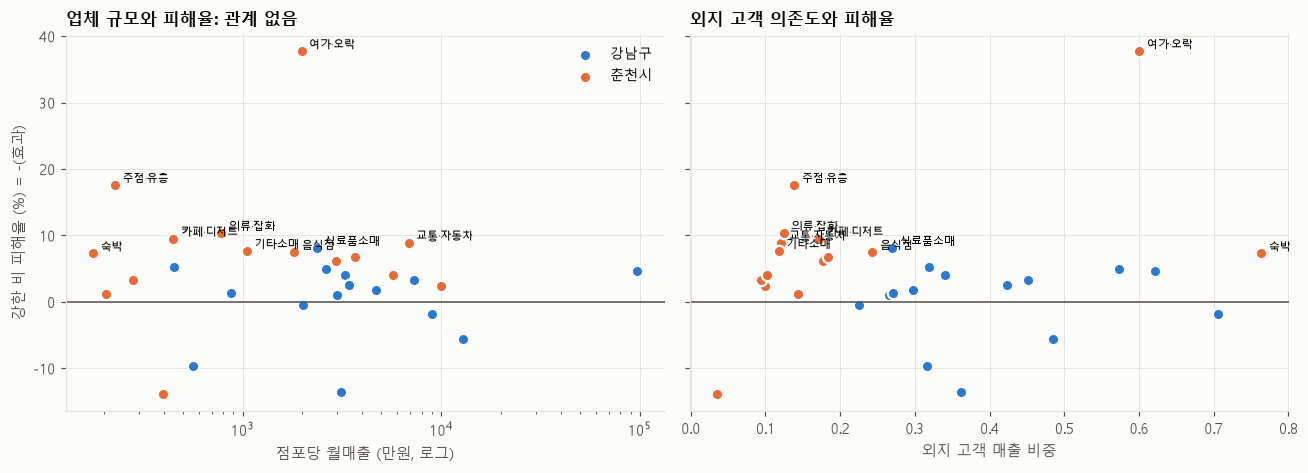

In [15]:
X = ue[['outsider_share', 'indep_share', 'log_size', 'evening_share']].copy()
Xz = (X - X.mean()) / X.std()
Xz['is_chuncheon'] = (ue['region'] == '춘천시').astype(int)
meta = sm.WLS(ue['b_rain_heavy'], sm.add_constant(Xz), weights=1 / ue['se_rain_heavy'] ** 2).fit(cov_type='HC1')
mt = pd.DataFrame({'계수(log, 1SD당)': meta.params, '효과(%p)': (np.exp(meta.params) - 1) * 100,
                   'p값': meta.pvalues}).drop(index='const')
mt.index = ['외지 고객 비중', '독립점포 비중', 'log 점포당 매출(규모)', '저녁 매출 비중', '춘천(지역)']
print(f'메타 회귀 (30개 단위, 가중 R² = {meta.rsquared:.2f})')
display(mt.round(4))

cc_u = ue[ue['region'] == '춘천시']
Xc = cc_u[['outsider_share', 'indep_share', 'log_size']]
Xc = (Xc - Xc.mean()) / Xc.std()
meta_cc = sm.WLS(cc_u['b_rain_heavy'], sm.add_constant(Xc), weights=1 / cc_u['se_rain_heavy'] ** 2).fit(cov_type='HC1')
mt_cc = pd.DataFrame({'계수(log, 1SD당)': meta_cc.params, '효과(%p)': (np.exp(meta_cc.params) - 1) * 100,
                      'p값': meta_cc.pvalues}).drop(index='const')
mt_cc.index = ['외지 고객 비중', '독립점포 비중', 'log 점포당 매출(규모)']
print('춘천 15개 업종만 (지역 차이를 뺀 업종 간 차이)')
display(mt_cc.round(4))
rho_size, p_size = spearmanr(ue['log_size'], -ue['eff_rain_heavy'])
rho_out, p_out = spearmanr(ue['outsider_share'], -ue['eff_rain_heavy'])
print(f'피해율(−강한 비 효과)과 점포 규모의 순위 상관 ρ = {rho_size:.2f} (p = {p_size:.2f}) | 외지 비중과 ρ = {rho_out:.2f} (p = {p_out:.2f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (col, label, logx) in zip(axes, [('sales_per_store_monthly', '점포당 월매출 (만원, 로그)', True),
                                         ('outsider_share', '외지 고객 매출 비중', False)]):
    for r in REGIONS:
        d = ue[ue['region'] == r]
        x = d[col] / (1e4 if col.startswith('sales') else 1)
        ax.scatter(x, -d['eff_rain_heavy'], s=55, color=REGION_COLOR[r], edgecolor=SURFACE, linewidth=1.5, label=r)
        for _, row in d[(-d['eff_rain_heavy']) > 7].iterrows():
            ax.annotate(row['industry_group'], (row[col] / (1e4 if col.startswith('sales') else 1), -row['eff_rain_heavy']),
                        textcoords='offset points', xytext=(5, 2), fontsize=7.5)
    if logx:
        ax.set_xscale('log')
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xlabel(label)
axes[0].set_ylabel('강한 비 피해율 (%) = -(효과)')
axes[0].set_title('업체 규모와 피해율: 관계 없음', fontsize=11)
axes[1].set_title('외지 고객 의존도와 피해율', fontsize=11)
axes[0].legend()
fig.tight_layout()

**CH5 판정 — 지지 (규모 ≠ 타격)**
- **업체 규모(점포당 매출)는 피해율을 설명하지 못한다** (30개 단위 메타 회귀 p = 0.86, 순위 상관 ρ = −0.22, p = 0.24).
- 피해율 차이를 가장 크게 만드는 것은 **지역(춘천 −6.7%p, p = 0.035)**, 즉 춘천의 방문객 상권 구조다. 업종 단위 외지 고객 비중은 30개 전체에서는 유의하지 않지만, **춘천 안에서는** 외지 비중이 1SD 높을수록 강한 비 효과가 약 −9%p 더 크다 (p ≈ 0.10, 업종이 15개라 경계선). 외지 이탈 경로 자체는 고객 단위(CH4)에서 확실하게 확인되었다.
- 이 결과의 의미가 중요하다: 피해율이 규모와 무관하면, **피해 '금액'(= 매출 × 피해율)은 거의 규모에 비례**한다. 따라서 '피해액이 큰 순'으로 지원하면 사실상 **'매출이 큰 순'** 지원이 되어, 피해율이 높은 소규모 방문객 업종이 뒤로 밀린다 (H1·H2의 인과적 근거).

## 8. 문제 발굴로의 연결 — '피해를 어떻게 재느냐'에 따라 지원 대상이 바뀐다

현실의 피해 판단은 대개 **"비 온 날 매출이 평소보다 얼마나 낮았나"**처럼 단순 비교로 이루어진다. 이 측정과 인과 추정이 얼마나 다른지, 그 차이로 **지원 대상이 어떻게 달라지는지** 확인한다.

| 측정 방식 | 정의 | 현실의 예 |
|---|---|---|
| **단순 비교** | 같은 달·같은 요일 유형(평일/휴일)의 비 없는 날 평균 대비 강한 비 날 매출 | 신고·체감 기반 피해 판단 |
| **인과 추정** | 주 고정효과·요일·공휴일 통제, 다른 기상 동시 통제 (7-1절) | 이 노트북 |

'피해 업종' 판정 기준: 효과 ≤ −5% (단순 비교) / 효과 ≤ −5% **그리고** FDR q < 0.10 (인과 추정 — 우연이 아닌 피해만)

In [16]:
rows = []
for (r, g), d in daily.groupby(KEYS):
    base = d[(d['rain_sum'] == 0) & (d['heat_33'] == 0)].groupby(['month', 'is_offday'])['log_amt'].mean().rename('base')
    x = d.join(base, on=['month', 'is_offday'])
    out = {'region': r, 'industry_group': g}
    for t, mask in [('rain_heavy', x['rain_heavy'] == 1), ('heat_33', (x['heat_33'] == 1) & (x['rain_sum'] == 0))]:
        out[f'naive_{t}'] = (np.exp((x.loc[mask, 'log_amt'] - x.loc[mask, 'base']).mean()) - 1) * 100
    rows.append(out)
cmp = ue.merge(pd.DataFrame(rows), on=KEYS)

cmp['naive_damage'] = cmp['naive_rain_heavy'] <= -5
cmp['causal_damage'] = (cmp['eff_rain_heavy'] <= -5) & (cmp['q_rain_heavy'] < 0.10)
conf = pd.crosstab(cmp['naive_damage'].map({True: '단순 비교: 피해', False: '단순 비교: 피해 아님'}),
                   cmp['causal_damage'].map({True: '인과: 피해', False: '인과: 피해 아님'}))
rho_nc = spearmanr(cmp['naive_rain_heavy'], cmp['eff_rain_heavy'])[0]
print(f'강한 비 효과 — 단순 비교 vs 인과 추정의 순위 상관 ρ = {rho_nc:.2f}')
display(conf)
mis = cmp[cmp['naive_damage'] != cmp['causal_damage']].sort_values('naive_rain_heavy')
mis[KEYS + ['naive_rain_heavy', 'eff_rain_heavy', 'q_rain_heavy']].rename(
    columns={'naive_rain_heavy': '단순 비교(%)', 'eff_rain_heavy': '인과 추정(%)', 'q_rain_heavy': 'FDR q'}).round(3)

강한 비 효과 — 단순 비교 vs 인과 추정의 순위 상관 ρ = 0.81


causal_damage,인과: 피해,인과: 피해 아님
naive_damage,,
단순 비교: 피해,8,2
단순 비교: 피해 아님,1,19


,region,industry_group,단순 비교(%),인과 추정(%),FDR q
18,춘천시,기타소매,-10.313,-7.636,0.118
1,강남구,교육,-6.135,-1.055,0.744
0,강남구,간편식,-1.802,-5.328,0.010


폭염: 단순 비교로 |효과| ≥ 5%인 업종 11개 → 인과 추정으로 유의한 업종 1개


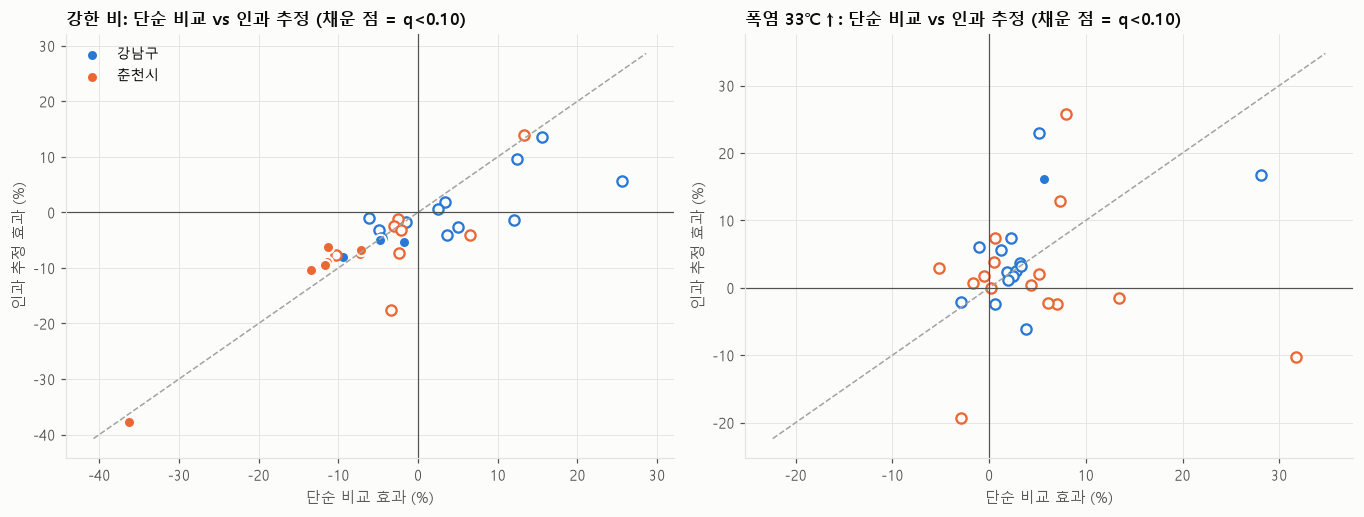

In [17]:
heat_naive = (cmp['naive_heat_33'].abs() >= 5).sum()
heat_causal = ((cmp['eff_heat_33'].abs() >= 5) & (cmp['q_heat_33'] < 0.10)).sum()
print(f'폭염: 단순 비교로 |효과| ≥ 5%인 업종 {heat_naive}개 → 인과 추정으로 유의한 업종 {heat_causal}개')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, t, title in [(axes[0], 'rain_heavy', '강한 비'), (axes[1], 'heat_33', '폭염 33℃↑')]:
    for r in REGIONS:
        d = cmp[cmp['region'] == r]
        sig = d[f'q_{t}'] < 0.10
        ax.scatter(d.loc[~sig, f'naive_{t}'], d.loc[~sig, f'eff_{t}'], s=45, facecolor=SURFACE, edgecolor=REGION_COLOR[r], lw=1.5)
        ax.scatter(d.loc[sig, f'naive_{t}'], d.loc[sig, f'eff_{t}'], s=55, color=REGION_COLOR[r], edgecolor=SURFACE, lw=1.5, label=r)
    lim = [min(cmp[f'naive_{t}'].min(), cmp[f'eff_{t}'].min()) - 3, max(cmp[f'naive_{t}'].max(), cmp[f'eff_{t}'].max()) + 3]
    ax.plot(lim, lim, color=MUTED, ls='--', lw=1)
    ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlabel('단순 비교 효과 (%)'); ax.set_ylabel('인과 추정 효과 (%)')
    ax.set_title(f'{title}: 단순 비교 vs 인과 추정 (채운 점 = q<0.10)', fontsize=11)
axes[0].legend(loc='upper left')
fig.tight_layout()

### 8-1. 금액 기준 vs 피해율 기준 — 같은 인과 효과로도 대상이 갈린다
인과 추정 피해율에 업종 규모를 곱한 **강한 비 하루 피해액**과 **피해율**로 각각 상위 8개 업종을 고르면 얼마나 겹치는가.

In [18]:
pos = cmp[cmp['eb_rain_heavy'] < 0].copy()
pos['rate'] = -pos['eb_rain_heavy']                                   # 축소된 인과 피해율 (%)
pos['loss_day'] = pos['base_daily_sales'] * pos['rate'] / 100         # 업종 전체 하루 피해액
pos['loss_store'] = pos['loss_day'] / pos['n_stores']
pos = pos[pos['industry_group'] != '대형유통']                         # 소상공인 지원 취지
top_amt = set(pos.nlargest(8, 'loss_day')[KEYS].apply(' '.join, axis=1))
top_rate = set(pos.nlargest(8, 'rate')[KEYS].apply(' '.join, axis=1))
print(f"대상 {len(pos)}개 단위 (대형유통 제외, 인과 피해율 > 0)")
print(f"피해액 상위 8 ∩ 피해율 상위 8 = {len(top_amt & top_rate)}개: {sorted(top_amt & top_rate)}")
print(f"피해율 상위인데 금액 기준이면 빠지는 업종: {sorted(top_rate - top_amt)}")
print(f"피해액 순위 vs 피해율 순위 ρ = {spearmanr(pos['loss_day'], pos['rate'])[0]:.2f}")

대상 22개 단위 (대형유통 제외, 인과 피해율 > 0)
피해액 상위 8 ∩ 피해율 상위 8 = 4개: ['강남구 식료품소매', '춘천시 교통·자동차', '춘천시 여가·오락', '춘천시 음식점']
피해율 상위인데 금액 기준이면 빠지는 업종: ['춘천시 의류·잡화', '춘천시 주점·유흥', '춘천시 카페·디저트', '춘천시 편의점']
피해액 순위 vs 피해율 순위 ρ = 0.20


**문제 발굴로의 연결 (6단계에서 정식화)**
1. **피해를 단순 비교로 재면 판정이 흔들린다.** 강한 비는 단순 비교와 인과 추정의 순위가 대체로 맞지만(ρ = 0.81), 30개 중 3개 업종은 '피해 업종' 판정이 뒤바뀐다 (강남 교육은 단순 비교로 −6.1%지만 인과적으로 −1.1%·유의하지 않음, 강남 간편식은 반대). **폭염은 더 심각하다**: 단순 비교로는 11개 업종이 ±5% 넘게 영향을 받는 것처럼 보이지만, 인과적으로 유의한 업종은 1개뿐이다 — 폭염 '피해'를 근거로 지원하면 대부분 계절 효과에 지원하는 셈이다.
2. **피해를 정확히 재도 '금액'으로 줄 세우면 엉뚱한 곳에 간다.** 피해율은 규모와 무관하므로(CH5), 피해액 순위와 피해율 순위의 상관은 0.20에 그친다. 피해율 상위 8개 중 절반(춘천 의류·잡화·주점·유흥·카페·디저트·편의점)이 금액 기준이면 빠진다.
3. → **"기후에 따른 매출 피해를 정확히 알지 못하면, 정말 필요한 곳에 지원하지 못한다."** 이를 해결하려면 ① 인과적으로 타당한 **피해 예측**, ② 규모가 아닌 타격을 반영한 **취약도 지수**, ③ 그 결과에 기반한 **지원금 최적화**가 필요하다 (3~5단계).

## 9. 가설 판정 종합·저장

In [19]:
def fmt(e, lo, hi):
    return f'{e:+.1f}% [{lo:+.1f}, {hi:+.1f}]'

g = lambda df, **kw: df.loc[np.logical_and.reduce([df[k] == v for k, v in kw.items()])].iloc[0]
cc1 = g(ch1, region='춘천시', spec='기본(이산)', term=WEATHER['rain_heavy'])
gn1 = g(ch1, region='강남구', spec='기본(이산)', term=WEATHER['rain_heavy'])
ri_cc = g(ri, region='춘천시', term=WEATHER['rain_heavy'])
es_cc = pd.DataFrame(es_tests).set_index('region')
cr_cc = g(cross, region='춘천시', term=WEATHER['rain_heavy'])
heat_reloc = reloc[reloc['term'] == WEATHER['heat_33']].set_index('region')
ch3_all = ch3[ch3['spec'] == '전체 시간대'].set_index('region')
ddd = g(ch4, 설계='삼중 차분')
cc4 = g(ch4, region='춘천시', term=WEATHER['rain_heavy'])

H = pd.DataFrame([
    {'id': 'CH1', '인과 가설': '강한 비(30mm↑)는 매출을 줄인다', '식별 전략': '주 고정효과, 선행 위약, 무작위화 추론, 지역 간 차분',
     '핵심 결과': (f"춘천 {fmt(cc1.effect_pct, cc1.ci_low, cc1.ci_high)}, RI p={ri_cc['RI p값 (양측)']:.3f}, "
                f"선행 결합 p={es_cc.loc['춘천시', 'p값']:.2f}, 지역 간 차분 {cr_cc.effect_pct:+.1f}% / 강남 {fmt(gn1.effect_pct, gn1.ci_low, gn1.ci_high)}"),
     '판정': '지지 (춘천) / 보류 (강남)'},
    {'id': 'CH2', '인과 가설': '폭염의 매출 증가는 교란이고, 인과 효과는 업종 간 소비 이동이다', '식별 전략': '통제 수준 비교, 선행 위약, 업종 가중합 검정',
     '핵심 결과': '; '.join(f"{r}: 업종 차이 p={heat_reloc.loc[r, '① 업종 간 차이 검정 p값']:.3f}, 가중 평균 {heat_reloc.loc[r, '② 매출 가중 평균 효과(%)']:+.1f}% (p={heat_reloc.loc[r, '② 평균 효과 p값']:.2f})" for r in REGIONS),
     '판정': ''},
    {'id': 'CH3', '인과 가설': '비는 내리는 시간대의 매출을 줄인다', '식별 전략': '날짜×업종 고정효과 + 업종×시간대 고정효과 (같은 날 안 비교)',
     '핵심 결과': '; '.join(f"{r} {fmt(ch3_all.loc[r, 'effect_pct'], ch3_all.loc[r, 'ci_low'], ch3_all.loc[r, 'ci_high'])}" for r in REGIONS),
     '판정': ''},
    {'id': 'CH4', '인과 가설': '춘천 호우 피해는 외지 고객 이탈에서 나온다', '식별 전략': '고객 출신 차분(날짜 공통 충격 제거), 삼중 차분, 손실 분해',
     '핵심 결과': (f"춘천 외지−현지 {cc4['차이(%p, log×100)']:+.1f}%p (p={cc4.p_value:.3f}), 삼중 차분 {ddd['차이(%p, log×100)']:+.1f}%p (p={ddd.p_value:.3f}), "
                f"손실 중 외지 몫 {decomp.set_index('region').loc['춘천시', '손실 중 외지 몫(%)']:.0f}%"),
     '판정': ''},
    {'id': 'CH5', '인과 가설': '피해율은 업체 규모로 설명되지 않는다 (규모 ≠ 타격)', '식별 전략': '단위별 인과 효과의 정밀도 가중 메타 회귀',
     '핵심 결과': (f"규모 계수 p={mt.loc['log 점포당 매출(규모)', 'p값']:.2f} (ρ={rho_size:.2f}), 지역(춘천) {mt.loc['춘천(지역)', '효과(%p)']:+.1f}%p "
                f"(p={mt.loc['춘천(지역)', 'p값']:.3f}), 춘천 내 외지 비중 {mt_cc.loc['외지 고객 비중', '효과(%p)']:+.1f}%p/SD (p={mt_cc.loc['외지 고객 비중', 'p값']:.2f})"),
     '판정': ''},
])
H.loc[H['id'] == 'CH2', '판정'] = ('지지' if (heat_reloc['① 업종 간 차이 검정 p값'] < 0.05).all()
                                    and (heat_reloc['② 평균 효과 p값'] > 0.05).all() else '부분 지지')
H.loc[H['id'] == 'CH3', '판정'] = ('지지' if (ch3_all['p_value'] < 0.05).all() and (ch3_all['effect_pct'] < 0).all()
                                    else '판단 보류 (방향 일치, 같은 날 안 비교에서 유의하지 않음)')
H.loc[H['id'] == 'CH4', '판정'] = '지지' if (cc4.p_value < 0.05 and ddd.p_value < 0.05 and ddd.coef < 0) else '부분 지지'
H.loc[H['id'] == 'CH5', '판정'] = '지지' if mt.loc['log 점포당 매출(규모)', 'p값'] > 0.05 else '기각'
H.to_csv(REF / 'causal_hypotheses.csv', index=False, encoding='utf-8-sig')
H[['id', '인과 가설', '판정', '핵심 결과']]

,id,인과 가설,판정,핵심 결과
0,CH1,강한 비(30mm↑)는 매출을 줄인다,지지 (춘천) / 보류 (강남),"춘천 -7.2% [-9.6, -4.8], RI p=0.002, 선행 결합 p=0.1..."
1,CH2,"폭염의 매출 증가는 교란이고, 인과 효과는 업종 간 소비 이동이다",부분 지지,"강남구: 업종 차이 p=0.002, 가중 평균 +2.6% (p=0.47); 춘천시:..."
2,CH3,비는 내리는 시간대의 매출을 줄인다,"판단 보류 (방향 일치, 같은 날 안 비교에서 유의하지 않음)","강남구 -1.3% [-7.3, +5.1]; 춘천시 -4.7% [-10.3, +1.4]"
3,CH4,춘천 호우 피해는 외지 고객 이탈에서 나온다,지지,"춘천 외지−현지 -18.5%p (p=0.000), 삼중 차분 -18.0%p (p=0..."
4,CH5,피해율은 업체 규모로 설명되지 않는다 (규모 ≠ 타격),지지,"규모 계수 p=0.86 (ρ=-0.22), 지역(춘천) -6.7%p (p=0.035..."


In [20]:
save = cmp[KEYS + ['b_rain_heavy', 'se_rain_heavy', 'eff_rain_heavy', 'q_rain_heavy', 'eb_rain_heavy',
                   'b_rain_mid', 'se_rain_mid', 'eff_rain_mid', 'q_rain_mid', 'eb_rain_mid',
                   'b_heat_33', 'se_heat_33', 'eff_heat_33', 'q_heat_33', 'eb_heat_33',
                   'naive_rain_heavy', 'naive_heat_33', 'naive_damage', 'causal_damage',
                   'outsider_share', 'indep_share', 'evening_share', 'sales_per_store_monthly', 'n_stores', 'base_daily_sales']]
save.to_parquet(PROC / 'causal_unit_effects.parquet', index=False)
print('저장:', PROC / 'causal_unit_effects.parquet', save.shape)
print('저장:', REF / 'causal_hypotheses.csv')

저장: C:\Users\CoBa\bigcontest_2026\cda_analysis\data\processed\causal_unit_effects.parquet (30, 27)
저장: C:\Users\CoBa\bigcontest_2026\cda_analysis\references\causal_hypotheses.csv


## 정리

| 항목 | 결과 |
|---|---|
| 식별의 핵심 | 날씨는 외생적 처치. 계절(휴가철) 교란은 **주 고정효과**로 차단, 유동인구·외지 고객은 매개 변수라 통제하지 않음 |
| **CH1 호우 → 매출 감소 (지지·춘천)** | 춘천 −7.2%: 선행 위약(비 오기 전 효과 없음, p = 0.18)·무작위화 추론(p = 0.002)·지역 간 차분(−8.1%)이 모두 같은 결론. 강남은 방향만 같고 확정 근거 부족 |
| **CH2 폭염 (부분 지지)** | 폭염이 매출을 줄인다는 근거 없음. 강남은 업종 간 소비 이동(업종 차이 유의·평균 0), 춘천은 영향 자체가 불확실. 폭염 기간이 휴가철에 몰려 인과 분리가 어려움 |
| **CH3 영업시간 강수 (보류)** | 같은 날 안 비교에서 춘천 −4.7%로 방향은 맞으나 유의하지 않음 → 강수 변수는 예측 성능으로 선택 |
| **CH4 외지 이탈 (지지)** | 춘천 외지−현지 −18.5%p, 삼중 차분 −18.0%p (모두 p < 0.001). 매출 18%인 외지 고객이 강한 비 손실의 53%를 차지 → **방문 수요 이탈이 메커니즘** |
| **CH5 규모 ≠ 타격 (지지)** | 피해율은 규모와 무관(p = 0.86), 지역(춘천)이 가장 큰 차이 → 피해액 순 지원 = 매출 순 지원 |
| 문제 발굴 연결 | 단순 비교는 폭염 피해를 11개 업종에서 '보이게' 하지만 인과적으로는 1개. 금액 기준이면 피해율 상위 8개 중 4개가 빠짐 (순위 상관 0.20) |
| 산출물 | `data/processed/causal_unit_effects.parquet`, `references/causal_hypotheses.csv` |

### 다음 단계에 넘기는 것
| 다음 단계 | 이 노트북의 근거 |
|---|---|
| 2. 데이터 엔지니어링 | 처치 변수는 **호우 중심**. 강수는 일강수량·영업시간 강수 노출을 **둘 다 후보**로(CH3 보류). 이질성 변수로 **지역·외지 비중**(CH4·CH5). 예측 모델에서는 주 고정효과를 쓸 수 없으므로 최근 매출 수준·평년값 등으로 계절성 대체 |
| 3. 피해 예측 | 반사실 = '비 없는 같은 날'. 비 온 다음 날 뚜렷한 반등은 없었으나(3-2) 순손실은 논문 방법으로 다시 확인 |
| 4. 취약도 지수 | 피해율의 결정 요인 = 지역(방문객 상권)·외지 의존, 규모 아님 → 지수에 **노출(외지 의존)**과 **피해율**을 넣고, 규모는 피해율 계산의 분모로만 쓴다 |
| 5. 지원금 최적화 | 피해액이 아닌 **피해율** 기준, 춘천 방문객 업종은 **방문 수요 보전** 수단 |

### 참고문헌
- Dell, M., Jones, B. F., & Olken, B. A. (2014). What Do We Learn from the Weather? The New Climate-Economy Literature. *Journal of Economic Literature*, 52(3), 740–798. — 날씨를 외생적 처치로 쓰는 패널 고정효과 설계
- Roth Tran, B. (2023). Sellin' in the Rain: Weather, Climate, and Retail Sales. *Management Science*, 69(12). — 날씨의 선행·시차 효과(위약·기간 간 대체)
- Imbens, G. W., & Rubin, D. B. (2015). *Causal Inference for Statistics, Social, and Biomedical Sciences*. Cambridge University Press. 5장 — Fisher 무작위화 추론
- Angrist, J. D., & Pischke, J.-S. (2009). *Mostly Harmless Econometrics*. Princeton University Press. 3.2.3절 — 나쁜 통제(결과 변수의 매개 변수를 통제하지 않음)